# 09: Compare detectors

Reads the saved test predictions of several runs and reports, per method:
- **Real:** fraction of real test images correctly called real
- **Detection rate** per generator: fraction of that generator's images called fake (threshold 0.5)
- **ROC-AUC** per generator: real images vs that generator's images (no threshold)

No GPU needed.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

ROOT = Path("/content/drive/MyDrive/minor-project")

Mounted at /content/drive


## Settings

In [2]:
RUNS = {
    "M1 ResNet-50": "e2_m1_sd15",
    "M2 CLIP": "e2_m2_sd15",
    "M3 NPR": "e2_m3_sd15",
}
SEEN = ["SD15"]          # generators used for training
OUT = "e2"               # prefix for saved files
GENERATORS = SEEN + [g for g in ["ADM", "GLIDE", "Midjourney", "SD15", "VQDM", "Wukong"] if g not in SEEN]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]

## Per-generator results

In [3]:
rows = []
for method, run in RUNS.items():
    pred = pd.read_csv(ROOT / "results" / f"{run}_test_predictions.csv")
    real = pred[pred["generator"] == "Real"]
    row = {"method": method, "real_correct": float((real["prob_fake"] < 0.5).mean())}
    for g in GENERATORS:
        fake = pred[pred["generator"] == g]
        both = pd.concat([real, fake])
        row[f"{g}_detected"] = float((fake["prob_fake"] >= 0.5).mean())
        row[f"{g}_auc"] = float(roc_auc_score(both["y"], both["prob_fake"]))
    unseen = [g for g in GENERATORS if g not in SEEN]
    if unseen:
        row["unseen_mean_detected"] = float(np.mean([row[f"{g}_detected"] for g in unseen]))
        row["unseen_mean_auc"] = float(np.mean([row[f"{g}_auc"] for g in unseen]))
    rows.append(row)

summary = pd.DataFrame(rows).set_index("method")
summary.to_csv(ROOT / "results" / f"{OUT}_summary.csv")

detected = summary[["real_correct"] + [f"{g}_detected" for g in GENERATORS]]
detected.columns = ["Real"] + GENERATORS
auc = summary[[f"{g}_auc" for g in GENERATORS]]
auc.columns = GENERATORS
print("Correct rate (Real = called real, generators = called fake):")
display((detected * 100).round(1))
print("ROC-AUC, real vs each generator:")
display(auc.round(3))
if "unseen_mean_auc" in summary:
    print("Mean over unseen generators:")
    display(summary[["unseen_mean_detected", "unseen_mean_auc"]].round(3))

Correct rate (Real = called real, generators = called fake):


,Real,SD15,ADM,GLIDE,Midjourney,VQDM,Wukong
method,,,,,,,
M1 ResNet-50,97.6,97.8,22.0,61.4,76.8,28.0,84.6
M2 CLIP,98.1,97.6,65.4,75.8,95.0,72.4,92.0
M3 NPR,96.1,96.4,39.8,69.6,65.2,36.4,87.0


ROC-AUC, real vs each generator:


,SD15,ADM,GLIDE,Midjourney,VQDM,Wukong
method,,,,,,
M1 ResNet-50,0.997,0.824,0.956,0.972,0.848,0.983
M2 CLIP,0.997,0.964,0.981,0.994,0.974,0.993
M3 NPR,0.991,0.897,0.958,0.934,0.870,0.977


Mean over unseen generators:


,unseen_mean_detected,unseen_mean_auc
method,,
M1 ResNet-50,0.546,0.917
M2 CLIP,0.801,0.981
M3 NPR,0.596,0.927


## Charts

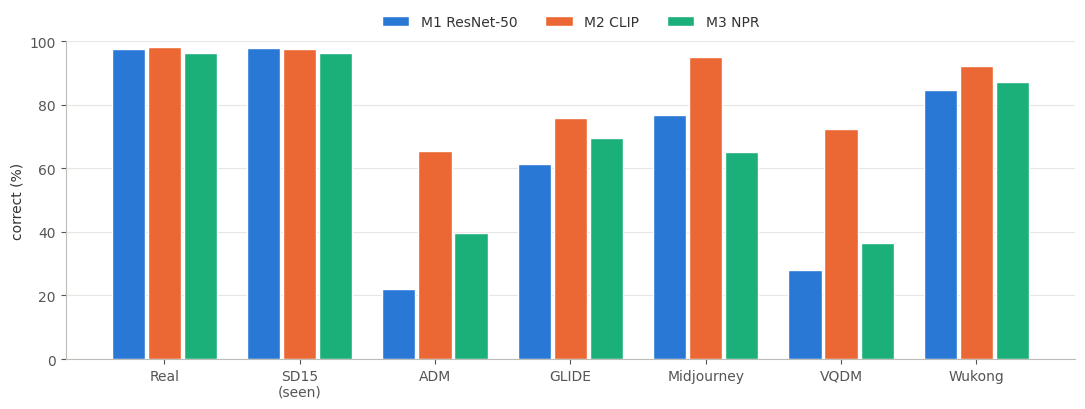

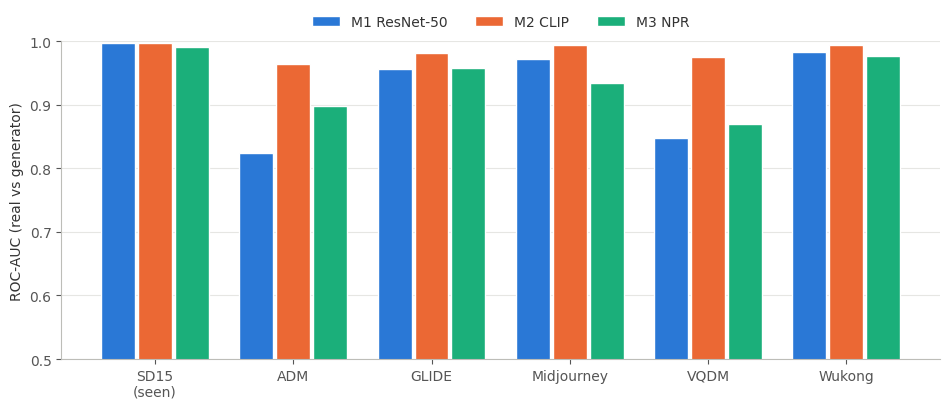

In [4]:
def grouped_bars(table, ylabel, ylim, filename):
    labels = [f"{c}\n(seen)" if c in SEEN else c for c in table.columns]
    n = len(table)
    width = 0.8 / n
    x = np.arange(len(table.columns))
    fig, ax = plt.subplots(figsize=(1.35 * len(table.columns) + 1.5, 4.2))
    for i, (method, values) in enumerate(table.iterrows()):
        ax.bar(x + (i - (n - 1) / 2) * width, values.to_numpy(), width=width * 0.92,
               color=COLORS[i], label=method, edgecolor="white", linewidth=1)
    ax.set_xticks(x, labels, color="#333333")
    ax.set_ylabel(ylabel, color="#333333")
    ax.set_ylim(*ylim)
    ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color("#bdbdb8")
    ax.tick_params(colors="#555555")
    ax.legend(frameon=False, ncol=n, loc="lower center", bbox_to_anchor=(0.5, 1.0), labelcolor="#333333")
    plt.tight_layout()
    plt.savefig(ROOT / "results" / filename, dpi=150)
    plt.show()


grouped_bars(detected * 100, "correct (%)", (0, 100), f"{OUT}_detection.png")
grouped_bars(auc, "ROC-AUC (real vs generator)", (0.5, 1.0), f"{OUT}_auc.png")